# SSAQS pilot: can wearables detect or predict high anxiety / stress days?
**Run top to bottom.** Everything is cached in `HCI_PROJECT/outputs/` on Drive, so re-runs are fast.

| Part | What it does |
|---|---|
| 1 | Load data, build 14-day windows, onset labels, baselines (LR / GBM / GRU), cross-university check |
| 2 | Diagnostics: within-person correlations, personalised features, bootstrap and permutation tests, calendar and block checks |
| 3 | Small KAN vs logistic regression, learned curves |
| 4 | Conformal prediction (90% coverage target) |

Design rules: students never appear in both train and test; features use only data up to the anchor day; personal baselines use past data only.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, warnings, pickle, hashlib, numpy as np, pandas as pd
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

# ---------------- CONFIG ----------------
ROOT = '/content/drive/MyDrive/HCI_PROJECT/SSAQS dataset'
TASKS = ['anxiety', 'stress']     # self-report column used as the label
THR = 50                          # "high day" cutoff on the 0-100 scale. Tune by looking at prevalence ONLY.
W = 14                            # input window (days)
HORIZONS = [1, 3, 7]              # predict onset within the next h days
QUIET_DAYS = 7                    # anchor must have no high day in the last 7 days (so it is an ONSET)
MIN_RECENT_LABELS = 2             # need >= 2 answered questionnaires in those 7 days
MIN_OBS_DAYS = 7                  # need >= 7 of 14 days with any Fitbit data
SEEDS = [0, 1, 2, 3, 4]
K_FOLDS = 5
RUN_GRU = True
USE_CACHE = True                  # reuse saved files from Drive; set False to recompute everything
FEATS = ['steps','sed_min','light_min','mod_min','vig_min','hrv','spo2','sleep_score','deep_sleep','fitbit_stress']
OUT = os.path.join(os.path.dirname(ROOT), 'outputs')      # -> /content/drive/MyDrive/HCI_PROJECT/outputs
os.makedirs(OUT, exist_ok=True)
SIG = hashlib.md5(repr((TASKS, THR, W, HORIZONS, QUIET_DAYS, MIN_RECENT_LABELS, MIN_OBS_DAYS, SEEDS, K_FOLDS, FEATS)).encode()).hexdigest()[:8]
def save_pkl(obj, name): pickle.dump(obj, open(os.path.join(OUT, name), 'wb'))
def load_pkl(name):
    p = os.path.join(OUT, name)
    return pickle.load(open(p, 'rb')) if (USE_CACHE and os.path.exists(p)) else None
print('outputs go to:', OUT, '| config signature:', SIG)

outputs go to: /content/drive/MyDrive/HCI_PROJECT/outputs | config signature: bee9a5a0


## 1. Load every student's folder into one daily table
Cleaning rules follow the SSAQS paper: drop failed Fitbit stress rows, flip the Fitbit stress score (higher = less stress in the raw file), keep SpO2 only in 95-100, nightly mean of HRV, daily step totals, minutes per activity level.

In [ ]:
def rd(path):
    if not os.path.exists(path): return None
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    return df

def parse_ts(s, offset=0):
    if pd.api.types.is_numeric_dtype(s):
        v = s.astype(float)
        if v.dropna().median() > 1e11: v = v / 1000.0       # milliseconds -> seconds
        return pd.to_datetime(v + offset, unit='s', errors='coerce')
    dt = pd.to_datetime(s, errors='coerce')
    if dt.dtype == object: dt = pd.to_datetime(s, errors='coerce', utc=True)
    if getattr(dt.dt, 'tz', None) is not None: dt = dt.dt.tz_localize(None)
    return dt

def offset_seconds(dq):
    off = pd.to_numeric(dq.get('timezoneoffset'), errors='coerce').median()
    if pd.isna(off): return 0.0
    if abs(off) <= 24: return off * 3600.0        # given in hours
    if abs(off) <= 1440: return off * 60.0        # given in minutes
    return float(off)                              # seconds (as in the paper)

def load_student(uid):
    d = os.path.join(ROOT, str(uid))
    dq = rd(os.path.join(d, 'daily_questions.csv'))
    if dq is None or not os.path.exists(os.path.join(d, 'steps.csv')): return None
    off = offset_seconds(dq)
    tscol = 'timestampsent' if 'timestampsent' in dq else dq.columns[0]
    dq['date'] = parse_ts(dq[tscol], off).dt.normalize()
    for c in ['stress', 'anxiety']: dq[c] = pd.to_numeric(dq[c], errors='coerce')
    lab = dq.dropna(subset=['date']).groupby('date')[['stress', 'anxiety']].mean()

    S = {}
    st = rd(os.path.join(d, 'steps.csv'))
    st['date'] = parse_ts(st['timestamp'], off).dt.normalize()
    S['steps'] = st.groupby('date')['steps'].sum()

    ac = rd(os.path.join(d, 'activity_level.csv'))
    ac['date'] = parse_ts(ac['timestamp'], off).dt.normalize()
    ct = pd.crosstab(ac['date'], ac['level'].astype(str).str.upper())
    for col, name in [('SEDENTARY','sed_min'),('LIGHTLY_ACTIVE','light_min'),('MODERATELY_ACTIVE','mod_min'),('VERY_ACTIVE','vig_min')]:
        S[name] = ct[col] if col in ct else pd.Series(dtype=float)

    hv = rd(os.path.join(d, 'hrv.csv'))
    hv['date'] = parse_ts(hv['timestamp'], off).dt.normalize()
    S['hrv'] = hv.groupby('date')['rmssd'].mean()

    ox = rd(os.path.join(d, 'oxygen.csv'))
    ox['date'] = parse_ts(ox['timestamp'], off).dt.normalize()
    ox = ox[(ox['value'] >= 95) & (ox['value'] <= 100)]
    S['spo2'] = ox.groupby('date')['value'].mean()

    sl = rd(os.path.join(d, 'sleep.csv'))
    sl['date'] = parse_ts(sl['timestamp'], off).dt.normalize()
    S['sleep_score'] = sl.groupby('date')['overall_score'].mean()
    S['deep_sleep'] = sl.groupby('date')['deep_sleep_in_minutes'].mean()

    fs = rd(os.path.join(d, 'stress.csv'))
    fs['date'] = pd.to_datetime(fs['date'], errors='coerce').dt.normalize()
    failed = fs['calculation_failed'].astype(str).str.upper().eq('TRUE')
    fs = fs[~failed & (pd.to_numeric(fs['stress_score'], errors='coerce') > 0)]
    S['fitbit_stress'] = (100 - pd.to_numeric(fs['stress_score'])).groupby(fs['date']).mean()   # flipped: higher = more stress

    allidx = [lab.index] + [s.index for s in S.values() if len(s)]
    lo = min(i.min() for i in allidx); hi = max(i.max() for i in allidx)
    days = pd.date_range(lo, hi, freq='D')
    df = pd.DataFrame(index=days)
    for f in FEATS: df[f] = S[f].reindex(days) if len(S[f]) else np.nan
    df['anxiety'] = lab['anxiety'].reindex(days)
    df['stress'] = lab['stress'].reindex(days)
    return df

uc = pd.read_csv(os.path.join(ROOT, 'users-courses.csv'))
uc.columns = [c.strip().lower() for c in uc.columns]
uni_of = dict(zip(uc['userid'], uc['university']))

students = load_pkl('cache_students.pkl')
if students is None:
    students = {}
    for uid in sorted(uc['userid']):
        try:
            df = load_student(uid)
        except Exception as e:
            print(f'student {uid}: FAILED -> {type(e).__name__}: {e}'); continue
        if df is None: print(f'student {uid}: no Fitbit files, skipped'); continue
        students[uid] = df
    save_pkl(students, 'cache_students.pkl')
    print(f'\nloaded {len(students)} students from CSVs and cached them')
else:
    print(f'loaded {len(students)} students from cache (delete cache_students.pkl or set USE_CACHE=False to reload CSVs)')

loaded 32 students from cache (delete cache_students.pkl or set USE_CACHE=False to reload CSVs)


In [ ]:
# DATA CHECK: coverage per student (fraction of days with data). Read this!
cov = pd.DataFrame({u: d[FEATS + ['anxiety','stress']].notna().mean() for u, d in students.items()}).T.round(2)
cov.insert(0, 'days', [len(d) for d in students.values()])
cov.insert(1, 'uni', [uni_of[u] for u in cov.index])
display(cov); cov.to_csv(os.path.join(OUT, 'data_coverage.csv'))
print('mean anxiety / stress:', np.nanmean([d['anxiety'].mean() for d in students.values()]).round(1),
      np.nanmean([d['stress'].mean() for d in students.values()]).round(1), ' (paper: 34.3 / 33.2)')
print('students per university:', pd.Series([uni_of[u] for u in students]).value_counts().to_dict())

,days,uni,steps,sed_min,light_min,mod_min,vig_min,hrv,spo2,sleep_score,deep_sleep,fitbit_stress,anxiety,stress
1,124,1,0.85,0.85,0.85,0.85,0.85,0.36,0.32,0.25,0.25,0.15,0.98,0.98
2,116,1,0.53,0.59,0.59,0.59,0.59,0.11,0.45,0.09,0.09,0.04,0.88,0.88
4,120,1,0.38,0.38,0.38,0.38,0.38,0.13,0.18,0.11,0.11,0.02,0.98,0.98
5,136,1,0.78,0.78,0.78,0.78,0.78,0.74,0.76,0.74,0.74,0.62,0.99,0.99
6,121,1,0.57,0.59,0.59,0.59,0.59,0.50,0.49,0.36,0.36,0.30,0.87,0.87
7,115,1,0.93,0.95,0.95,0.95,0.95,0.90,0.86,0.83,0.83,0.68,0.90,0.90
8,115,1,0.96,0.96,0.96,0.96,0.96,0.89,0.91,0.87,0.87,0.75,0.90,0.90
9,114,1,0.97,0.97,0.97,0.97,0.97,0.62,0.73,0.54,0.54,0.42,0.53,0.53
10,123,1,0.81,0.83,0.83,0.83,0.83,0.47,0.44,0.34,0.34,0.17,0.93,0.93
11,107,1,1.00,1.00,1.00,1.00,1.00,0.28,0.46,0.24,0.24,0.11,0.36,0.36


mean anxiety / stress: 36.4 34.8  (paper: 34.3 / 33.2)
students per university: {1: 17, 2: 15}


## 2. Build windows and onset labels
A window is **eligible** only if the student had no high day in the 7 days up to the anchor (so a positive is a *new* episode, not a continuing one). Label = a high day appears in the next *h* days (answered questionnaires only; `-1` = unknown).

In [ ]:
def build(task):
    Xs, Ms, Hs, Ys, G, U, T = [], [], [], [], [], [], []
    for uid, df in students.items():
        lab = df[task].values; F = df[FEATS].values.astype(float); n = len(df)
        for i in range(W - 1, n - 1):
            win = F[i - W + 1: i + 1]
            if (~np.isnan(win)).any(axis=1).sum() < MIN_OBS_DAYS: continue
            rec = lab[max(0, i - QUIET_DAYS + 1): i + 1]
            if (~np.isnan(rec)).sum() < MIN_RECENT_LABELS: continue
            if np.nanmax(rec) >= THR: continue
            ys = []
            for h in HORIZONS:
                fut = lab[i + 1: i + 1 + h]
                if i + h >= n or np.isnan(fut).all(): ys.append(-1)
                else: ys.append(int(np.nanmax(fut) >= THR))
            if all(y < 0 for y in ys): continue
            l14 = lab[max(0, i - 13): i + 1]; l7 = lab[max(0, i - 6): i + 1]
            last = l14[~np.isnan(l14)][-1]
            hist = [last, np.nanmean(l7), np.nanmax(l14), (~np.isnan(l14)).sum()]
            Xs.append(win); Ms.append(~np.isnan(win)); Hs.append(hist); Ys.append(ys)
            G.append(uid); U.append(uni_of[uid]); T.append(df.index[i])
    return dict(X=np.array(Xs), M=np.array(Ms), H=np.array(Hs), Y=np.array(Ys), G=np.array(G), U=np.array(U), T=np.array(T))

DATA = load_pkl(f'cache_windows_{SIG}.pkl')
if DATA is None:
    DATA = {t: build(t) for t in TASKS}; save_pkl(DATA, f'cache_windows_{SIG}.pkl')
else: print('windows loaded from cache')
rows = []
for t, D in DATA.items():
    for j, h in enumerate(HORIZONS):
        y = D['Y'][:, j]; ok = y >= 0
        rows.append(dict(task=t, horizon=h, windows=int(ok.sum()), positives=int(y[ok].sum()),
                         prevalence=round(y[ok].mean(), 3) if ok.any() else np.nan,
                         students_with_pos=len(set(D['G'][ok & (y == 1)]))))
POS = pd.DataFrame(rows); display(POS); POS.to_csv(os.path.join(OUT, 'positives_per_task_horizon.csv'), index=False)
print('RULE OF THUMB: fewer than ~30-50 positives => results are noise. Change THR / drop that horizon.')

windows loaded from cache


,task,horizon,windows,positives,prevalence,students_with_pos
0,anxiety,1,828,56,0.068,25
1,anxiety,3,915,154,0.168,25
2,anxiety,7,923,282,0.306,26
3,stress,1,969,56,0.058,26
4,stress,3,1082,139,0.128,26
5,stress,7,1083,257,0.237,26


RULE OF THUMB: fewer than ~30-50 positives => results are noise. Change THR / drop that horizon.


## 3. Features for the classical baselines
Per channel: 14-day mean, last-7-day mean, change (last 7 minus first 7), std, and missing rate. Plus a small "past self-report" set (last answer, 7-day mean, 14-day max, answers count).

In [ ]:
def summarize(X):
    with np.errstate(all='ignore'):
        mean = np.nanmean(X, axis=1); last7 = np.nanmean(X[:, -7:], axis=1)
        first7 = np.nanmean(X[:, :7], axis=1); std = np.nanstd(X, axis=1)
        miss = np.isnan(X).mean(axis=1)
    return np.hstack([mean, last7, last7 - first7, std, miss])

def make_lr(seed): return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                        LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000))
def make_gb(seed): return make_pipeline(SimpleImputer(strategy='median'),
                                        HistGradientBoostingClassifier(max_depth=3, max_iter=100, learning_rate=0.05,
                                                                       class_weight='balanced', random_state=seed))

def student_folds(g, seed, K):
    u = np.unique(g); rng = np.random.RandomState(seed); rng.shuffle(u)
    for part in np.array_split(u, min(K, len(u))):
        te = np.isin(g, part); yield ~te, te

def cv_score(fp, y, g):
    out = []
    for s in SEEDS:
        p = np.full(len(y), np.nan)
        for tr, te in student_folds(g, s, K_FOLDS):
            if len(np.unique(y[tr])) < 2: p[te] = y[tr].mean(); continue
            p[te] = fp(tr, te, s)
        ok = ~np.isnan(p)
        out.append((roc_auc_score(y[ok], p[ok]), average_precision_score(y[ok], p[ok])))
    return np.array(out)

def sk_fp(Xf, y, make):
    def fp(tr, te, s):
        m = make(s); m.fit(Xf[tr], y[tr]); return m.predict_proba(Xf[te])[:, 1]
    return fp

def heuristic_fp(H, y):
    def fp(tr, te, s):
        v = H[:, 0].copy(); v[np.isnan(v)] = np.nanmean(v[tr]); return v[te]   # score = last self-report
    return fp

In [ ]:
RESULTS = load_pkl(f'cache_results_{SIG}.pkl') or {}   # (task, horizon) -> {model: array(seeds, 2)}; finished models are skipped on re-run
for t, D in DATA.items():
    Wf = summarize(D['X'])
    for j, h in enumerate(HORIZONS):
        y_all = D['Y'][:, j]; ok = y_all >= 0
        y = y_all[ok]; g = D['G'][ok]; Wh = Wf[ok]; Hh = D['H'][ok]; Bh = np.hstack([Wh, Hh])
        if y.sum() < 10 or (1 - y).sum() < 10:
            print(f'[{t} h={h}] too few positives/negatives, skipped'); continue
        R = RESULTS.setdefault((t, h), {})
        jobs = {
            'heuristic: last self-report': lambda: cv_score(heuristic_fp(Hh, y), y, g),
            'LR  past self-report only':   lambda: cv_score(sk_fp(Hh, y, make_lr), y, g),
            'LR  wearable only':           lambda: cv_score(sk_fp(Wh, y, make_lr), y, g),
            'LR  both':                    lambda: cv_score(sk_fp(Bh, y, make_lr), y, g),
            'GBM wearable only':           lambda: cv_score(sk_fp(Wh, y, make_gb), y, g),
            'GBM both':                    lambda: cv_score(sk_fp(Bh, y, make_gb), y, g)}
        for name, fn in jobs.items():
            if name not in R: R[name] = fn()
        save_pkl(RESULTS, f'cache_results_{SIG}.pkl')
        print(f'done {t} h={h}  (n={len(y)}, pos={int(y.sum())})')

done anxiety h=1  (n=828, pos=56)
done anxiety h=3  (n=915, pos=154)
done anxiety h=7  (n=923, pos=282)
done stress h=1  (n=969, pos=56)
done stress h=3  (n=1082, pos=139)
done stress h=7  (n=1083, pos=257)


## 4. Optional: a small GRU on the raw 14-day sequence
This is the "does sequence order help?" check that sits between the simple baselines and the KAN-ODE.

In [ ]:
if RUN_GRU:
    import torch, torch.nn as nn
    torch.set_num_threads(2)
    class GRUNet(nn.Module):
        def __init__(self, d, hid=16):
            super().__init__(); self.gru = nn.GRU(d, hid, batch_first=True); self.fc = nn.Linear(hid, 1)
        def forward(self, x): return self.fc(self.gru(x)[0][:, -1]).squeeze(-1)

    def gru_fp(X, M, y, epochs=40):
        def fp(tr, te, s):
            torch.manual_seed(s)
            mu = np.nanmean(X[tr].reshape(-1, X.shape[2]), axis=0); sd = np.nanstd(X[tr].reshape(-1, X.shape[2]), axis=0) + 1e-6
            Z = np.nan_to_num((X - mu) / sd, nan=0.0)
            inp = torch.tensor(np.concatenate([Z, M.astype(float)], axis=2), dtype=torch.float32)
            yt = torch.tensor(y, dtype=torch.float32)
            net = GRUNet(inp.shape[2]); opt = torch.optim.Adam(net.parameters(), lr=1e-2, weight_decay=1e-3)
            pw = torch.tensor((1 - y[tr]).sum() / max(y[tr].sum(), 1), dtype=torch.float32)
            lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
            idx = np.where(tr)[0]
            for ep in range(epochs):
                np.random.RandomState(s * 1000 + ep).shuffle(idx)
                for b in range(0, len(idx), 128):
                    bi = idx[b:b + 128]; opt.zero_grad()
                    lossf(net(inp[bi]), yt[bi]).backward(); opt.step()
            with torch.no_grad(): return torch.sigmoid(net(inp[te])).numpy()
        return fp

    for t, D in DATA.items():
        for j, h in enumerate(HORIZONS):
            if (t, h) not in RESULTS: continue
            ok = D['Y'][:, j] >= 0
            if 'GRU wearable only' not in RESULTS[(t, h)]:
                RESULTS[(t, h)]['GRU wearable only'] = cv_score(gru_fp(D['X'][ok], D['M'][ok], D['Y'][ok, j]), D['Y'][ok, j], D['G'][ok])
                save_pkl(RESULTS, f'cache_results_{SIG}.pkl')
            print('GRU ready', t, h)

GRU ready anxiety 1
GRU ready anxiety 3
GRU ready anxiety 7
GRU ready stress 1
GRU ready stress 3
GRU ready stress 7


## 5. Results (mean ± std over 5 random student-level splits)
Compare each row to **prevalence**: a useless model gets AUC-PR ≈ prevalence and AUROC ≈ 0.5. The key question is whether `wearable only` beats chance, and whether `both` beats `past self-report only`.

In [ ]:
def fmt(a): return f'{a[:,0].mean():.3f}±{a[:,0].std():.3f} | {a[:,1].mean():.3f}±{a[:,1].std():.3f}'
lines, long = [], []
for (t, h), R in RESULTS.items():
    D = DATA[t]; j = HORIZONS.index(h); y = D['Y'][:, j]; y = y[y >= 0]
    lines.append(f'\n=== task={t}  horizon={h}d  n={len(y)}  positives={int(y.sum())}  prevalence={y.mean():.3f} ===')
    lines.append(f'{"model":32s} AUROC       | AUC-PR')
    for m, a in R.items():
        lines.append(f'{m:32s} {fmt(a)}')
        long.append(dict(task=t, horizon=h, model=m, n=len(y), positives=int(y.sum()), prevalence=round(y.mean(), 4),
                         auroc_mean=a[:, 0].mean(), auroc_std=a[:, 0].std(), aucpr_mean=a[:, 1].mean(), aucpr_std=a[:, 1].std()))
report = '\n'.join(lines); print(report)
pd.DataFrame(long).to_csv(os.path.join(OUT, f'results_cv_{SIG}.csv'), index=False)
open(os.path.join(OUT, f'results_report_{SIG}.txt'), 'w').write(f'THR={THR} W={W} horizons={HORIZONS}\n' + report)
print('\nsaved to', OUT)


=== task=anxiety  horizon=1d  n=828  positives=56  prevalence=0.068 ===
model                            AUROC       | AUC-PR
heuristic: last self-report      0.660±0.000 | 0.119±0.000
LR  past self-report only        0.737±0.004 | 0.171±0.004
LR  wearable only                0.501±0.012 | 0.077±0.006
LR  both                         0.632±0.021 | 0.122±0.011
GBM wearable only                0.465±0.028 | 0.066±0.010
GBM both                         0.652±0.028 | 0.123±0.014
GRU wearable only                0.505±0.034 | 0.082±0.017

=== task=anxiety  horizon=3d  n=915  positives=154  prevalence=0.168 ===
model                            AUROC       | AUC-PR
heuristic: last self-report      0.654±0.000 | 0.264±0.000
LR  past self-report only        0.746±0.005 | 0.370±0.029
LR  wearable only                0.535±0.024 | 0.183±0.010
LR  both                         0.670±0.022 | 0.307±0.030
GBM wearable only                0.515±0.064 | 0.178±0.032
GBM both                         0.67

## 6. External check: train on one university, test on the other
Directly addresses the "no external validation" gap in the review. Only 2 universities, ~16 students each, so treat as exploratory.

In [ ]:
rows = []
for t, D in DATA.items():
    Wf = summarize(D['X'])
    for j, h in enumerate(HORIZONS):
        y_all = D['Y'][:, j]; ok = y_all >= 0
        for a, b in [(1, 2), (2, 1)]:
            tr = ok & (D['U'] == a); te = ok & (D['U'] == b)
            if len(np.unique(y_all[tr])) < 2 or len(np.unique(y_all[te])) < 2: continue
            for name, Xf in [('LR past self-report', D['H']), ('LR wearable', Wf), ('LR both', np.hstack([Wf, D['H']]))]:
                m = make_lr(0); m.fit(Xf[tr], y_all[tr]); p = m.predict_proba(Xf[te])[:, 1]
                rows.append(dict(task=t, h=h, train_uni=a, test_uni=b, model=name, n_test=int(te.sum()), pos_test=int(y_all[te].sum()),
                                 AUROC=round(roc_auc_score(y_all[te], p), 3), AUCPR=round(average_precision_score(y_all[te], p), 3),
                                 prevalence=round(y_all[te].mean(), 3)))
XU = pd.DataFrame(rows); display(XU); XU.to_csv(os.path.join(OUT, f'results_cross_university_{SIG}.csv'), index=False)
print('saved to', OUT)

,task,h,train_uni,test_uni,model,n_test,pos_test,AUROC,AUCPR,prevalence
0,anxiety,1,1,2,LR past self-report,340,25,0.706,0.177,0.074
1,anxiety,1,1,2,LR wearable,340,25,0.600,0.142,0.074
2,anxiety,1,1,2,LR both,340,25,0.659,0.139,0.074
3,anxiety,1,2,1,LR past self-report,488,31,0.714,0.145,0.064
4,anxiety,1,2,1,LR wearable,488,31,0.472,0.065,0.064
5,anxiety,1,2,1,LR both,488,31,0.519,0.072,0.064
6,anxiety,3,1,2,LR past self-report,367,65,0.725,0.418,0.177
7,anxiety,3,1,2,LR wearable,367,65,0.643,0.309,0.177
8,anxiety,3,1,2,LR both,367,65,0.706,0.345,0.177
9,anxiety,3,2,1,LR past self-report,548,89,0.727,0.319,0.162


saved to /content/drive/MyDrive/HCI_PROJECT/outputs


## Reading the results honestly
- `wearable only` ≈ chance (AUROC ~0.5, AUC-PR ~ prevalence) → wearables carry little signal here. That is a valid pilot finding (the SSAQS paper itself reports r = 0.048 between Fitbit stress and self-reported stress).
- `both` > `past self-report only` by a margin larger than the ± std → wearables add value.
- Do **not** build the KAN-ODE unless `wearable only` or `GRU` clearly beats chance at some horizon.

---
# PART 2: Diagnostics - is there ANY wearable signal?
Uses the `students` table already loaded above (no reloading). Five checks: (1) within-person correlations, (2) personalised features, (3) fewer channels, (4) 'personal high day' labels at lead 0/1/3 days, (5) bootstrap + permutation tests.


In [ ]:
from scipy.stats import spearmanr
import matplotlib; import matplotlib.pyplot as plt

# Part-2 settings (everything else - ROOT, OUT, TASKS, SEEDS, K_FOLDS, FEATS, students - comes from Part 1)
LEADS = [0, 1, 3]          # wearable day = target day - lead (0 = same day)
MIN_PAST = 10              # past answers needed before a day counts (personal baseline)
NBOOT = 500; NPERM = 1000     # NPERM=1000 takes ~15 min in total; use 100 for a quick test run
ACT = ['steps','sed_min','light_min','mod_min','vig_min']
print(len(students), 'students available;', 'outputs ->', OUT)


32 students available; outputs -> /content/drive/MyDrive/HCI_PROJECT/outputs


## Check 1. Within-person correlations (each student vs their own days)
Per student: Spearman correlation between the wearable value on day *d − lead* and the self-report on day *d*. Then average over students with a bootstrap CI over students. With 10 channels × 3 leads × 2 tasks = 60 tests, a few CIs excluding 0 are expected by chance.

,task,lead,channel,n_students,mean_rho,ci_lo,ci_hi,share_positive
1,anxiety,0,sed_min,31,0.146,0.085,0.205,0.806
8,anxiety,0,deep_sleep,24,-0.074,-0.133,-0.010,0.250
17,anxiety,1,sleep_score,24,-0.047,-0.095,-0.002,0.375
31,stress,0,sed_min,31,0.161,0.094,0.222,0.871
37,stress,0,sleep_score,24,-0.061,-0.115,-0.007,0.333
38,stress,0,deep_sleep,24,-0.073,-0.129,-0.024,0.333
41,stress,1,sed_min,31,0.081,0.020,0.142,0.742
47,stress,1,sleep_score,24,-0.068,-0.118,-0.015,0.250


8 of 60 correlations have a 95% CI excluding 0 (about 3 expected by chance alone)


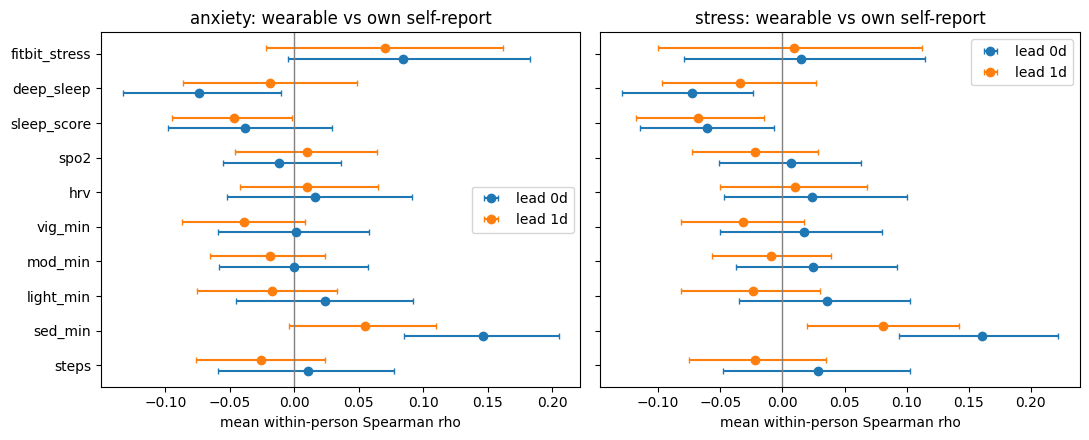

In [ ]:
def boot_ci(v, n=1000, seed=0):
    v = np.asarray(v); rng = np.random.RandomState(seed)
    m = [v[rng.randint(0, len(v), len(v))].mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

rows = []
for task in TASKS:
    for lead in LEADS:
        for ch in FEATS:
            rhos = []
            for uid, df in students.items():
                x = df[ch].shift(lead); y = df[task]; ok = x.notna() & y.notna()
                if ok.sum() >= 20 and x[ok].nunique() > 1 and y[ok].nunique() > 1:
                    rhos.append(spearmanr(x[ok], y[ok])[0])
            if len(rhos) < 8: continue
            lo, hi = boot_ci(rhos)
            rows.append(dict(task=task, lead=lead, channel=ch, n_students=len(rhos), mean_rho=np.mean(rhos),
                             ci_lo=lo, ci_hi=hi, share_positive=np.mean(np.array(rhos) > 0)))
COR = pd.DataFrame(rows).round(3); COR.to_csv(os.path.join(OUT, 'diag_channel_correlations.csv'), index=False)
COR['ci_excludes_0'] = (COR.ci_lo > 0) | (COR.ci_hi < 0)
display(COR[COR.ci_excludes_0].drop(columns='ci_excludes_0'))
print(f'{COR.ci_excludes_0.sum()} of {len(COR)} correlations have a 95% CI excluding 0 (about {0.05*len(COR):.0f} expected by chance alone)')

fig, axes = plt.subplots(1, len(TASKS), figsize=(11, 4.5), sharey=True)
for ax, task in zip(np.atleast_1d(axes), TASKS):
    for k, lead in enumerate([0, 1]):
        d = COR[(COR.task == task) & (COR.lead == lead)].set_index('channel').reindex(FEATS).dropna(subset=['mean_rho'])
        pos = np.arange(len(d)) + (k - 0.5) * 0.3
        ax.errorbar(d.mean_rho, [FEATS.index(c) + (k - 0.5) * 0.3 for c in d.index],
                    xerr=[d.mean_rho - d.ci_lo, d.ci_hi - d.mean_rho], fmt='o', capsize=2, label=f'lead {lead}d')
    ax.axvline(0, color='gray', lw=1); ax.set_title(f'{task}: wearable vs own self-report'); ax.set_xlabel('mean within-person Spearman rho')
    ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'diag_channel_correlations.png'), dpi=150); plt.show()

## Checks 2-4. Personalised features and 'personal high day' labels
Target on day *d*: self-report ≥ the student's **own past** mean + 1 SD (past only, needs ≥ 10 past answers). Wearable features = deviation from the student's own past baseline (z-score) for the last day, last-3-day mean and last-7-day mean. Past self-report features use answers up to day *d − 1* only.

In [ ]:
def zfeat(s, base, sd, roll, minp):
    v = s if roll == 1 else s.rolling(roll, min_periods=minp).mean()
    return ((v - base) / sd).replace([np.inf, -np.inf], np.nan)

def build_day_level(task, lead):
    Wall, SR, Y, G, Dates = [], [], [], [], []
    for uid, df in students.items():
        a = df[task]
        base = a.shift(1).expanding(min_periods=MIN_PAST).mean(); sd = a.shift(1).expanding(min_periods=MIN_PAST).std()
        sr = pd.DataFrame({'sr_z1': zfeat(a, base, sd, 1, 1), 'sr_z3': zfeat(a, base, sd, 3, 2), 'sr_base': base})
        W = {}
        for c in FEATS:
            s = df[c]; wb = s.shift(1).expanding(min_periods=MIN_PAST).mean(); ws = s.shift(1).expanding(min_periods=MIN_PAST).std()
            W[f'{c}_z1'] = zfeat(s, wb, ws, 1, 1); W[f'{c}_z3'] = zfeat(s, wb, ws, 3, 2); W[f'{c}_z7'] = zfeat(s, wb, ws, 7, 3)
        W = pd.DataFrame(W)
        hi = (a >= base + sd).astype(float).where(a.notna() & base.notna() & sd.notna())
        Wd = W.shift(lead); Sd = sr.shift(1)
        keep = hi.notna() & (Wd.notna().sum(axis=1) >= 3)
        Wall.append(Wd[keep]); SR.append(Sd[keep]); Y.append(hi[keep].values); G += [uid] * int(keep.sum()); Dates.append(df.index[keep])
    Wall = pd.concat(Wall); SR = pd.concat(SR); Dates = pd.DatetimeIndex(np.concatenate(Dates))
    act_cols = [c for c in Wall.columns if c.rsplit('_z', 1)[0] in ACT]
    return dict(Wall=Wall.values, Wact=Wall[act_cols].values, SR=SR.values, y=np.concatenate(Y).astype(int), g=np.array(G), date=Dates)

def make_lr_diag(): return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                    LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000))
def folds_diag(g, seed, K):
    u = np.unique(g); rng = np.random.RandomState(seed); rng.shuffle(u)
    for part in np.array_split(u, min(K, len(u))):
        te = np.isin(g, part); yield ~te, te
def oof_diag(X, y, g, seed):
    p = np.full(len(y), np.nan)
    for tr, te in folds_diag(g, seed, K_FOLDS):
        if len(np.unique(y[tr])) < 2: p[te] = y[tr].mean(); continue
        m = make_lr_diag(); m.fit(X[tr], y[tr]); p[te] = m.predict_proba(X[te])[:, 1]
    return p

DAY = {}; rows = []; OOF = {}
for task in TASKS:
    for lead in LEADS:
        D = build_day_level(task, lead); DAY[(task, lead)] = D
        y, g = D['y'], D['g']
        sets = {'past self-report': D['SR'], 'wearable steps+activity': D['Wact'], 'wearable all': D['Wall'],
                'past + steps+activity': np.hstack([D['SR'], D['Wact']]), 'past + all': np.hstack([D['SR'], D['Wall']])}
        print(f'{task} lead={lead}d: rows={len(y)}  positives={y.sum()}  prevalence={y.mean():.3f}  students={len(np.unique(g))}')
        for name, X in sets.items():
            aucs, prs = [], []
            for s in SEEDS:
                p = oof_diag(X, y, g, s); aucs.append(roc_auc_score(y, p)); prs.append(average_precision_score(y, p))
                if s == 0: OOF[(task, lead, name)] = p
            rows.append(dict(task=task, lead=lead, model=name, n=len(y), prevalence=round(y.mean(), 3),
                             AUROC=np.mean(aucs), AUROC_sd=np.std(aucs), AUCPR=np.mean(prs), AUCPR_sd=np.std(prs)))
MOD = pd.DataFrame(rows).round(3); MOD.to_csv(os.path.join(OUT, 'diag_models.csv'), index=False)
display(MOD)

anxiety lead=0d: rows=2183  positives=457  prevalence=0.209  students=31
anxiety lead=1d: rows=2178  positives=451  prevalence=0.207  students=31
anxiety lead=3d: rows=2166  positives=447  prevalence=0.206  students=31
stress lead=0d: rows=2183  positives=408  prevalence=0.187  students=31
stress lead=1d: rows=2178  positives=403  prevalence=0.185  students=31
stress lead=3d: rows=2166  positives=398  prevalence=0.184  students=31


,task,lead,model,n,prevalence,AUROC,AUROC_sd,AUCPR,AUCPR_sd
0,anxiety,0,past self-report,2183,0.209,0.720,0.007,0.448,0.008
1,anxiety,0,wearable steps+activity,2183,0.209,0.589,0.006,0.291,0.007
2,anxiety,0,wearable all,2183,0.209,0.572,0.003,0.277,0.004
3,anxiety,0,past + steps+activity,2183,0.209,0.715,0.007,0.454,0.008
4,anxiety,0,past + all,2183,0.209,0.709,0.006,0.446,0.009
5,anxiety,1,past self-report,2178,0.207,0.722,0.007,0.447,0.009
6,anxiety,1,wearable steps+activity,2178,0.207,0.560,0.006,0.258,0.008
7,anxiety,1,wearable all,2178,0.207,0.533,0.008,0.231,0.008
8,anxiety,1,past + steps+activity,2178,0.207,0.718,0.008,0.441,0.009
9,anxiety,1,past + all,2178,0.207,0.703,0.007,0.425,0.011


## Check 5. Is any wearable model better than chance? Does it add to past self-report?
- **Bootstrap over students** (resample whole students) gives a CI that reflects the small number of people.
- **Permutation test**: shuffle the labels within each student and repeat; the p-value is the share of shuffles that score as well as the real model.
- **Δ AUROC** = (past + wearable) minus (past only), with a student-level bootstrap CI.

In [ ]:
def student_boot(y, p_list, g, n=NBOOT, seed=0):
    ug = np.unique(g); idx = {u: np.where(g == u)[0] for u in ug}; rng = np.random.RandomState(seed)
    out = [[] for _ in p_list]
    for _ in range(n):
        ii = np.concatenate([idx[u] for u in rng.choice(ug, len(ug))])
        if len(np.unique(y[ii])) < 2: continue
        for k, p in enumerate(p_list): out[k].append(roc_auc_score(y[ii], p[ii]))
    return [np.array(o) for o in out]

def perm_p(X, y, g, obs, n=NPERM, seed=0):
    rng = np.random.RandomState(seed); idx = {u: np.where(g == u)[0] for u in np.unique(g)}; cnt = 0
    for _ in range(n):
        yp = y.copy()
        for ii in idx.values(): yp[ii] = y[rng.permutation(ii)]
        if len(np.unique(yp)) < 2: continue
        if roc_auc_score(yp, oof_diag(X, yp, g, 0)) >= obs: cnt += 1
    return (1 + cnt) / (1 + n)

rows = []
for (task, lead), D in DAY.items():
    y, g = D['y'], D['g']
    past = OOF[(task, lead, 'past self-report')]
    for wname, Xw, bname in [('wearable steps+activity', D['Wact'], 'past + steps+activity'), ('wearable all', D['Wall'], 'past + all')]:
        pw = OOF[(task, lead, wname)]; pb = OOF[(task, lead, bname)]
        bw, bb, bp = student_boot(y, [pw, pb, past], g)
        n = min(len(bw), len(bb), len(bp)); dlt = bb[:n] - bp[:n]
        obs = roc_auc_score(y, pw)
        rows.append(dict(task=task, lead=lead, wearable_set=wname, wearable_AUROC=obs,
                         ci_lo=np.percentile(bw, 2.5), ci_hi=np.percentile(bw, 97.5), perm_p=perm_p(Xw, y, g, obs),
                         delta_over_past=roc_auc_score(y, pb) - roc_auc_score(y, past),
                         delta_ci_lo=np.percentile(dlt, 2.5), delta_ci_hi=np.percentile(dlt, 97.5)))
TEST = pd.DataFrame(rows).round(3); TEST.to_csv(os.path.join(OUT, 'diag_wearable_tests.csv'), index=False)
display(TEST)
sig = TEST[(TEST.perm_p < 0.05) & (TEST.ci_lo > 0.5)]
add = TEST[TEST.delta_ci_lo > 0]
print('\nWearable-only models with perm p < 0.05 AND CI above 0.5:', len(sig), 'of', len(TEST))
print('Wearable sets that add to past self-report (delta CI above 0):', len(add), 'of', len(TEST))
print('(12 tests were run: one or two "hits" can be luck. Look for the SAME channel set working in both tasks or at several leads.)')

,task,lead,wearable_set,wearable_AUROC,ci_lo,ci_hi,perm_p,delta_over_past,delta_ci_lo,delta_ci_hi
0,anxiety,0,wearable steps+activity,0.590,0.540,0.634,0.001,-0.005,-0.016,0.005
1,anxiety,0,wearable all,0.569,0.524,0.617,0.001,-0.014,-0.028,-0.001
2,anxiety,1,wearable steps+activity,0.563,0.517,0.609,0.019,-0.004,-0.012,0.004
3,anxiety,1,wearable all,0.531,0.489,0.576,0.093,-0.021,-0.040,-0.007
4,anxiety,3,wearable steps+activity,0.568,0.510,0.625,0.004,-0.002,-0.013,0.009
5,anxiety,3,wearable all,0.545,0.496,0.599,0.022,-0.012,-0.031,0.005
6,stress,0,wearable steps+activity,0.593,0.533,0.647,0.001,-0.003,-0.017,0.010
7,stress,0,wearable all,0.578,0.519,0.632,0.001,-0.013,-0.029,-0.001
8,stress,1,wearable steps+activity,0.581,0.525,0.629,0.001,-0.002,-0.010,0.005
9,stress,1,wearable all,0.558,0.506,0.600,0.005,-0.012,-0.024,-0.001



Wearable-only models with perm p < 0.05 AND CI above 0.5: 10 of 12
Wearable sets that add to past self-report (delta CI above 0): 0 of 12
(12 tests were run: one or two "hits" can be luck. Look for the SAME channel set working in both tasks or at several leads.)


## How to read the verdict
- **No hits** in the permutation and Δ tables, and no consistent correlations in Check 1 → no usable wearable signal here. Report it as an honest pilot result. Do **not** build the KAN-ODE to rescue it.
- **Same-day (lead 0) works but lead 1 and 3 do not** → wearables reflect today's state but don't forecast. Report that as detection, not prediction.
- **A consistent hit** (same channel set, both tasks, or several leads) → build a small KAN model on exactly those channels and compare with the logistic baseline here.

---
## Check 6. Is the small wearable signal real, or just shared calendar / time trends?
Part 2 found a weak signal in steps + activity. Two things could fake it: (a) anxiety and activity both drift with the semester and the week (exams, Easter, weekends), and (b) the label-shuffle test ignores that neighbouring days are alike, so its p-values are too optimistic. This cell tests both:
- **Calendar-only model**: week of year + day of week, nothing from the wearable. If it scores like the wearable model, the "signal" is the calendar.
- **Wearable + calendar vs calendar**: does the wearable add anything once the calendar is known? (student-level bootstrap CI)
- **Block permutation**: shift each student's labels along time by a random amount (keeps the day-to-day similarity), then re-score.
- **Sedentary fraction**: sedentary minutes / all worn minutes, to check the sedentary result is not just wear time.


In [ ]:
def cal_matrix(dates):
    di = pd.DatetimeIndex(dates)
    wk = pd.get_dummies(di.isocalendar().week.astype(int).values).astype(float).values
    dw = pd.get_dummies(di.dayofweek).astype(float).values
    return np.hstack([wk, dw])

def block_perm_p(X, y, g, obs, n=NPERM, seed=0):
    rng = np.random.RandomState(seed); idx = {u: np.where(g == u)[0] for u in np.unique(g)}; cnt = 0
    for _ in range(n):
        yp = y.copy()
        for ii in idx.values(): yp[ii] = np.roll(y[ii], rng.randint(1, max(len(ii), 2)))
        if len(np.unique(yp)) < 2: continue
        if roc_auc_score(yp, oof_diag(X, yp, g, 0)) >= obs: cnt += 1
    return (1 + cnt) / (1 + n)

rows = []
for (task, lead), D in DAY.items():
    y, g = D['y'], D['g']; cal = cal_matrix(D['date']); Xw = D['Wact']
    p_w = OOF[(task, lead, 'wearable steps+activity')]; p_c = oof_diag(cal, y, g, 0); p_wc = oof_diag(np.hstack([Xw, cal]), y, g, 0)
    a_w, a_c, a_wc = roc_auc_score(y, p_w), roc_auc_score(y, p_c), roc_auc_score(y, p_wc)
    b_wc, b_c = student_boot(y, [p_wc, p_c], g); n = min(len(b_wc), len(b_c)); d = b_wc[:n] - b_c[:n]
    rows.append(dict(task=task, lead=lead, wearable_AUROC=a_w, calendar_only_AUROC=a_c, wearable_plus_calendar=a_wc,
                     delta_over_calendar=a_wc - a_c, delta_ci_lo=np.percentile(d, 2.5), delta_ci_hi=np.percentile(d, 97.5),
                     block_perm_p_wearable=block_perm_p(Xw, y, g, a_w)))
C6 = pd.DataFrame(rows).round(3); C6.to_csv(os.path.join(OUT, 'diag_calendar_and_block_tests.csv'), index=False); display(C6)

# sedentary fraction
rows = []
for task in TASKS:
    for lead in [0, 1]:
        rhos = []
        for uid, df in students.items():
            tot = df[['sed_min','light_min','mod_min','vig_min']].sum(axis=1, min_count=4)
            x = (df['sed_min'] / tot.where(tot > 0)).shift(lead); yv = df[task]; ok = x.notna() & yv.notna()
            if ok.sum() >= 20 and x[ok].nunique() > 1 and yv[ok].nunique() > 1: rhos.append(spearmanr(x[ok], yv[ok])[0])
        lo, hi = boot_ci(rhos); rows.append(dict(task=task, lead=lead, n_students=len(rhos), mean_rho=np.mean(rhos), ci_lo=lo, ci_hi=hi, share_positive=np.mean(np.array(rhos) > 0)))
SF = pd.DataFrame(rows).round(3); SF.to_csv(os.path.join(OUT, 'diag_sedentary_fraction.csv'), index=False); display(SF)
print('\nReading: wearable signal is only credible if (1) calendar-only AUROC is clearly lower, (2) delta_over_calendar CI is above 0 or block_perm_p < 0.05, (3) sedentary fraction still has a CI away from 0.')

,task,lead,wearable_AUROC,calendar_only_AUROC,wearable_plus_calendar,delta_over_calendar,delta_ci_lo,delta_ci_hi,block_perm_p_wearable
0,anxiety,0,0.590,0.534,0.576,0.041,-0.001,0.084,0.002
1,anxiety,1,0.563,0.534,0.559,0.025,-0.011,0.058,0.037
2,anxiety,3,0.568,0.528,0.558,0.030,-0.013,0.073,0.023
3,stress,0,0.593,0.545,0.578,0.033,-0.013,0.071,0.001
4,stress,1,0.581,0.547,0.572,0.025,-0.011,0.053,0.002
5,stress,3,0.582,0.538,0.572,0.035,-0.000,0.066,0.003


,task,lead,n_students,mean_rho,ci_lo,ci_hi,share_positive
0,anxiety,0,31,0.100,0.034,0.165,0.645
1,anxiety,1,31,0.076,0.016,0.139,0.677
2,stress,0,31,0.094,0.021,0.166,0.677
3,stress,1,31,0.078,0.026,0.127,0.806



Reading: wearable signal is only credible if (1) calendar-only AUROC is clearly lower, (2) delta_over_calendar CI is above 0 or block_perm_p < 0.05, (3) sedentary fraction still has a CI away from 0.


---
# PART 3: Small KAN vs logistic regression
3a is a first KAN with 7 channels and 8 hidden units (it overfits). 3b is a smaller, more regularised KAN (all 4 configurations are reported, none cherry-picked). 3c draws its learned curves, fitted on all students for shape only, with the logistic slope for reference.

In [ ]:
# ===== PART 3a: small KAN on personalised wearable features =====
import torch, torch.nn as nn
torch.set_num_threads(2)

KAN_LEADS = [0, 1]
KAN_CH = ['steps', 'sed_min', 'light_min', 'mod_min', 'vig_min', 'sleep_score', 'deep_sleep']
NAMES = [f'{c}_{k}' for c in FEATS for k in ('z1', 'z3', 'z7')]       # same order as build_day_level
KAN_IDX = [i for i, n in enumerate(NAMES) if n.rsplit('_z', 1)[0] in KAN_CH]
KAN_NAMES = [NAMES[i] for i in KAN_IDX]
ACT_IDX = [i for i, n in enumerate(NAMES) if n.rsplit('_z', 1)[0] in ['steps', 'sed_min', 'light_min', 'mod_min', 'vig_min']]
KAN_H, KAN_G, KAN_EPOCHS, KAN_LAM = 8, 8, 60, 1e-3      # hidden units, basis functions, epochs, regularisation
assert DAY[(TASKS[0], 1)]['Wall'].shape[1] == len(NAMES), 'column layout changed'

class KANLayer(nn.Module):
    # y_o = sum_i phi_oi(x_i) + b_o ; phi = learnable curve (Gaussian-RBF basis) + linear SiLU skip (FastKAN-style)
    def __init__(self, n_in, n_out, G=8, lo=-3., hi=3.):
        super().__init__()
        self.register_buffer('c', torch.linspace(lo, hi, G)); self.h = (hi - lo) / (G - 1)
        self.coef = nn.Parameter(torch.randn(n_out, n_in, G) * 0.1)
        self.w = nn.Parameter(torch.randn(n_out, n_in) / np.sqrt(n_in)); self.b = nn.Parameter(torch.zeros(n_out))
    def forward(self, x):
        basis = torch.exp(-((x.unsqueeze(-1) - self.c) / self.h) ** 2)           # (B, n_in, G)
        return torch.einsum('bik,oik->bo', basis, self.coef) + nn.functional.silu(x) @ self.w.T + self.b
    def reg(self): return self.coef.abs().mean() + (self.coef[..., 1:] - self.coef[..., :-1]).pow(2).mean()

class KANNet(nn.Module):
    def __init__(self, n_in, H=8, G=8):
        super().__init__(); self.l1 = KANLayer(n_in, H, G); self.l2 = KANLayer(H, 1, G)
    def forward(self, x): return self.l2(torch.tanh(self.l1(x))).squeeze(-1)    # returns logits

def prep(X): return np.nan_to_num(np.clip(X, -4, 4), nan=0.0)                  # z-scores: clip, missing -> 0 (= own usual)

def train_kan(X, y, seed, epochs=KAN_EPOCHS, lam=KAN_LAM):
    torch.manual_seed(seed); rng = np.random.RandomState(seed)
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
    net = KANNet(X.shape[1], KAN_H, KAN_G); opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y).sum() / max(y.sum(), 1), dtype=torch.float32))
    for ep in range(epochs):
        perm = rng.permutation(len(y))
        for b in range(0, len(y), 128):
            bi = perm[b:b + 128]; opt.zero_grad()
            (lossf(net(Xt[bi]), yt[bi]) + lam * (net.l1.reg() + net.l2.reg())).backward(); opt.step()
    return net.eval()

def predict_kan(net, X):
    with torch.no_grad(): return torch.sigmoid(net(torch.tensor(X, dtype=torch.float32))).numpy()

def kan_oof(X, y, g, seed):
    p = np.full(len(y), np.nan)
    for tr, te in folds_diag(g, seed, K_FOLDS):
        if len(np.unique(y[tr])) < 2: p[te] = y[tr].mean(); continue
        p[te] = predict_kan(train_kan(X[tr], y[tr], seed), X[te])
    return p

rows = []
for task in TASKS:
    for lead in KAN_LEADS:
        D = DAY[(task, lead)]; y, g = D['y'], D['g']
        Xraw = D['Wall'][:, KAN_IDX]; Xk = prep(Xraw)
        res = {'KAN (steps+activity+sleep)': [], 'LR  (same features)': []}
        for s in SEEDS:
            pk = kan_oof(Xk, y, g, s); pl = oof_diag(Xraw, y, g, s)
            res['KAN (steps+activity+sleep)'].append((roc_auc_score(y, pk), average_precision_score(y, pk)))
            res['LR  (same features)'].append((roc_auc_score(y, pl), average_precision_score(y, pl)))
        for name, v in res.items():
            v = np.array(v); rows.append(dict(task=task, lead=lead, model=name, prevalence=round(y.mean(), 3),
                AUROC=v[:, 0].mean(), AUROC_sd=v[:, 0].std(), AUCPR=v[:, 1].mean(), AUCPR_sd=v[:, 1].std()))
        print('done', task, lead)
KANRES = pd.DataFrame(rows).round(3); KANRES.to_csv(os.path.join(OUT, 'kan_vs_lr.csv'), index=False); display(KANRES)

done anxiety 0
done anxiety 1
done stress 0
done stress 1


,task,lead,model,prevalence,AUROC,AUROC_sd,AUCPR,AUCPR_sd
0,anxiety,0,KAN (steps+activity+sleep),0.209,0.530,0.010,0.234,0.006
1,anxiety,0,LR (same features),0.209,0.576,0.011,0.284,0.008
2,anxiety,1,KAN (steps+activity+sleep),0.207,0.534,0.007,0.232,0.008
3,anxiety,1,LR (same features),0.207,0.541,0.011,0.245,0.011
4,stress,0,KAN (steps+activity+sleep),0.187,0.543,0.010,0.225,0.007
5,stress,0,LR (same features),0.187,0.591,0.008,0.279,0.015
6,stress,1,KAN (steps+activity+sleep),0.185,0.515,0.014,0.210,0.010
7,stress,1,LR (same features),0.185,0.562,0.010,0.247,0.013


In [ ]:
# ===== PART 3b: smaller, more regularised KAN. ALL configs are reported, no cherry-picking =====
CONFIGS = [dict(H=2, lam=1e-2, ep=20), dict(H=4, lam=1e-2, ep=20), dict(H=2, lam=1e-1, ep=30), dict(H=4, lam=1e-1, ep=30)]
rows = []
for task in TASKS:
    for lead in KAN_LEADS:
        D = DAY[(task, lead)]; y, g = D['y'], D['g']
        Xraw = D['Wall'][:, ACT_IDX]; Xk = prep(Xraw)
        lr = [roc_auc_score(y, oof_diag(Xraw, y, g, s)) for s in SEEDS[:3]]
        rows.append(dict(task=task, lead=lead, config='LR (steps+activity)', AUROC=np.mean(lr), AUROC_sd=np.std(lr)))
        for cfg in CONFIGS:
            KAN_H = cfg['H']
            aucs = []
            for s in SEEDS[:3]:
                p = np.full(len(y), np.nan)
                for tr, te in folds_diag(g, s, K_FOLDS):
                    p[te] = predict_kan(train_kan(Xk[tr], y[tr], s, epochs=cfg['ep'], lam=cfg['lam']), Xk[te])
                aucs.append(roc_auc_score(y, p))
            rows.append(dict(task=task, lead=lead, config=f"KAN H={cfg['H']} lam={cfg['lam']} ep={cfg['ep']}", AUROC=np.mean(aucs), AUROC_sd=np.std(aucs)))
        print('done', task, lead)
KAN_H = 8
KANREG = pd.DataFrame(rows).round(3); KANREG.to_csv(os.path.join(OUT, 'kan_regularised.csv'), index=False); display(KANREG)

done anxiety 0
done anxiety 1
done stress 0
done stress 1


,task,lead,config,AUROC,AUROC_sd
0,anxiety,0,LR (steps+activity),0.589,0.002
1,anxiety,0,KAN H=2 lam=0.01 ep=20,0.581,0.007
2,anxiety,0,KAN H=4 lam=0.01 ep=20,0.579,0.008
3,anxiety,0,KAN H=2 lam=0.1 ep=30,0.587,0.005
4,anxiety,0,KAN H=4 lam=0.1 ep=30,0.583,0.006
5,anxiety,1,LR (steps+activity),0.562,0.002
6,anxiety,1,KAN H=2 lam=0.01 ep=20,0.569,0.004
7,anxiety,1,KAN H=4 lam=0.01 ep=20,0.571,0.005
8,anxiety,1,KAN H=2 lam=0.1 ep=30,0.575,0.011
9,anxiety,1,KAN H=4 lam=0.1 ep=30,0.576,0.007


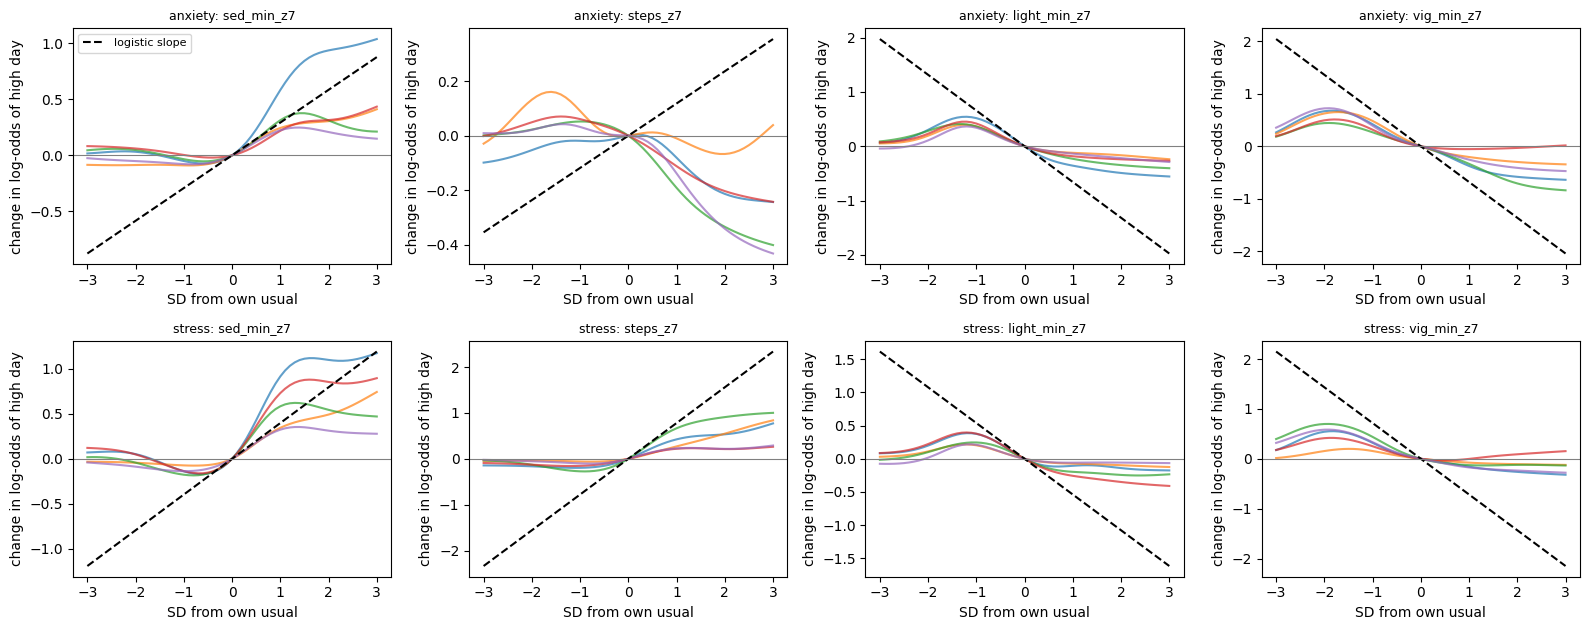

,task,feature,mean_seed_corr,logistic_slope
0,anxiety,sed_min_z7,0.925,0.292
1,anxiety,steps_z7,0.832,0.118
2,anxiety,light_min_z7,0.983,-0.658
3,anxiety,vig_min_z7,0.950,-0.682
4,stress,sed_min_z7,0.966,0.397
5,stress,steps_z7,0.960,0.779
6,stress,light_min_z7,0.932,-0.539
7,stress,vig_min_z7,0.915,-0.717


In [ ]:
# ===== PART 3c: curves from the SMALL regularised KAN (steps+activity only) + logistic slope for reference =====
KAN_H = 2
ACT_NAMES = [NAMES[i] for i in ACT_IDX]
PLOT_FEATS = [n for n in ['sed_min_z7', 'steps_z7', 'light_min_z7', 'vig_min_z7'] if n in ACT_NAMES]
LEAD_PLOT = 1
grid = np.linspace(-3, 3, 61)
fig, axes = plt.subplots(len(TASKS), len(PLOT_FEATS), figsize=(4 * len(PLOT_FEATS), 3.2 * len(TASKS)), squeeze=False)
stab = []
for r, task in enumerate(TASKS):
    D = DAY[(task, LEAD_PLOT)]; Xraw = D['Wall'][:, ACT_IDX]; Xk = prep(Xraw); y = D['y']
    nets = [train_kan(Xk, y, s, epochs=30, lam=1e-1) for s in SEEDS]       # all students: for SHAPE only, not for scoring
    lr = make_lr_diag(); lr.fit(Xraw, y); lr_coef = lr[-1].coef_[0] / lr[1].scale_    # logistic slope per unit of each feature
    for c, fname in enumerate(PLOT_FEATS):
        j = ACT_NAMES.index(fname); curves = []
        for net in nets:
            Z = np.zeros((len(grid), len(ACT_NAMES)), dtype=np.float32); Z[:, j] = grid
            with torch.no_grad(): lg = net(torch.tensor(Z)).numpy()
            curves.append(lg - lg[len(grid) // 2]); axes[r, c].plot(grid, curves[-1], alpha=0.7)
        axes[r, c].plot(grid, lr_coef[j] * grid, 'k--', lw=1.5, label='logistic slope')
        C = np.corrcoef(np.array(curves)); stab.append(dict(task=task, feature=fname, mean_seed_corr=C[np.triu_indices(len(SEEDS), 1)].mean(),
                                                           logistic_slope=lr_coef[j]))
        axes[r, c].axhline(0, color='gray', lw=0.8); axes[r, c].set_title(f'{task}: {fname}', fontsize=9)
        axes[r, c].set_xlabel('SD from own usual'); axes[r, c].set_ylabel('change in log-odds of high day')
        if r == 0 and c == 0: axes[r, c].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'kan_curves_small.png'), dpi=150); plt.show()
KAN_H = 8
STAB2 = pd.DataFrame(stab).round(3); STAB2.to_csv(os.path.join(OUT, 'kan_curve_stability_small.csv'), index=False); display(STAB2)

---
# PART 4: Conformal prediction
Class-conditional split conformal, split by student (60 / 20 / 20), 30 repeats, target coverage 90%. `coverage_pos` is coverage on truly high days. Per-university numbers are exploratory (about 15 students each).

In [ ]:
# ===== PART 4: conformal prediction (class-conditional split conformal, target coverage 90%) =====
ALPHA, N_REP = 0.10, 30
CONF_LEAD = 1

def conformal_run(X, y, g, alpha=ALPHA, n_rep=N_REP):
    rows, ug = [], np.unique(g); uni = np.array([uni_of[u] for u in g])
    for r in range(n_rep):
        u = np.random.RandomState(r).permutation(ug); n = len(u)
        te_u, ca_u, tr_u = u[:int(.2 * n)], u[int(.2 * n):int(.4 * n)], u[int(.4 * n):]      # split by STUDENT: 60 / 20 / 20
        tr, ca, te = np.isin(g, tr_u), np.isin(g, ca_u), np.isin(g, te_u)
        if len(np.unique(y[tr])) < 2 or y[ca].sum() < 5 or (1 - y[ca]).sum() < 5: continue
        m = make_lr_diag(); m.fit(X[tr], y[tr]); pc = m.predict_proba(X[ca])[:, 1]; pt = m.predict_proba(X[te])[:, 1]
        q = {}
        for k, sc in [(1, 1 - pc[y[ca] == 1]), (0, pc[y[ca] == 0])]:     # surprise = 1 - P(true label), cutoff per class
            lvl = min(1.0, np.ceil((len(sc) + 1) * (1 - alpha)) / len(sc)); q[k] = np.quantile(sc, lvl, method='higher')
        in1, in0 = (1 - pt) <= q[1], pt <= q[0]                          # does the set contain label 1 / label 0 ?
        yt = y[te]; cov = np.where(yt == 1, in1, in0)
        row = dict(coverage=cov.mean(), coverage_pos=cov[yt == 1].mean(), coverage_neg=cov[yt == 0].mean(),
                   avg_set_size=(in1.astype(int) + in0).mean(), share_not_sure=(in1 & in0).mean(),
                   share_empty=(~in1 & ~in0).mean(), share_single=(in1 ^ in0).mean())
        for uu in (1, 2):
            mk = uni[te] == uu
            if mk.sum() > 0: row[f'coverage_uni{uu}'] = cov[mk].mean()
        rows.append(row)
    return pd.DataFrame(rows)

out = []
for task in TASKS:
    D = DAY[(task, CONF_LEAD)]; y, g = D['y'], D['g']
    for name, X in [('past self-report', D['SR']), ('past + steps+activity', np.hstack([D['SR'], D['Wact']]))]:
        R = conformal_run(X, y, g)
        out.append(dict(task=task, model=name, reps=len(R), target=1 - ALPHA, **{c: f'{R[c].mean():.3f}±{R[c].std():.3f}' for c in R.columns}))
CONF = pd.DataFrame(out); CONF.to_csv(os.path.join(OUT, 'conformal_results.csv'), index=False); display(CONF.T)
print('coverage_pos = coverage on truly-high days (the one that matters). share_not_sure = sets containing both labels ("send to a human").')
print('Per-university coverage is EXPLORATORY: only ~15 students each, so those numbers are noisy.')

,0,1,2,3
task,anxiety,anxiety,stress,stress
model,past self-report,past + steps+activity,past self-report,past + steps+activity
reps,30,30,30,30
target,0.9,0.9,0.9,0.9
coverage,0.893±0.043,0.900±0.037,0.893±0.043,0.900±0.034
coverage_pos,0.899±0.101,0.902±0.087,0.916±0.068,0.925±0.058
coverage_neg,0.886±0.066,0.895±0.059,0.884±0.061,0.891±0.050
avg_set_size,1.619±0.106,1.630±0.093,1.607±0.104,1.658±0.099
share_not_sure,0.619±0.106,0.630±0.093,0.607±0.104,0.658±0.099
share_empty,0.000±0.000,0.000±0.000,0.000±0.000,0.000±0.000


coverage_pos = coverage on truly-high days (the one that matters). share_not_sure = sets containing both labels ("send to a human").
Per-university coverage is EXPLORATORY: only ~15 students each, so those numbers are noisy.


In [ ]:
# ===== Files saved in outputs/ =====
for f in sorted(os.listdir(OUT)):
    if not f.startswith('cache_'): print(f)

conformal_results.csv
data_coverage.csv
diag_calendar_and_block_tests.csv
diag_channel_correlations.csv
diag_channel_correlations.png
diag_models.csv
diag_sedentary_fraction.csv
diag_wearable_tests.csv
kan_curve_stability.csv
kan_curve_stability_small.csv
kan_curves.png
kan_curves_small.png
kan_regularised.csv
kan_vs_lr.csv
positives_per_task_horizon.csv
results_cross_university_bee9a5a0.csv
results_cv_bee9a5a0.csv
results_report_bee9a5a0.txt
